# DHVC Ra = 1e9 축소 상자 — 진행 상황과 통계

- 덱 `input_dhvc_1e9_box.ini`: 상자 4×2×1 (x 연직·y 스팬만 원래 8×4 의 절반), 격자 1600×332×1600 = 8.5억 셀 — 해상도는 `input_dhvc_1e9.ini`(3200×664×1600)와 같다.
  z(벽 간격)는 Ra 의 기준 길이라 줄이지 않았다.
- **1구간**: H200 ×6 (1×1×6), Ra 1e7 검증 런 체크포인트를 격자보간 warm-start, t 0 → 150. 통계 t 100 ~ 150 → `out_1e9_box/`.
- **2구간**: H200 ×2 (1×1×2), t 150 체크포인트에서 정확한 재시작(`input_dhvc_1e9_box_seg2.ini`), t 150 → 270. 통계를 재시작 직후부터 새로 누적 → `out_1e9_box_seg2/`.
- DHVC 는 재시작 때 통계를 복원하지 않는다 → 두 구간 파일을 **dt 가중으로 합친다** (평균은 그대로, rms·플럭스는 2차 모멘트로 되돌려 합친 뒤 다시 뺀다). §1b 첫 줄이 이 합산 식을 1구간 파일로 자체 검증한다.
- 모니터 열: Re_dstar 만 그 구간의 통계 누적값(구간마다 새로 시작), 나머지(Nu, u_τ, u_max)는 순간 평면 평균.
- 다시 만들기: `python3 apps/dhvc/plot/build_plot_1e9.py` (또는 이 노트북 셀을 다시 실행).

In [ ]:
import csv, datetime, glob, math, os, re, struct
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

APP = os.getcwd()   # apps/dhvc (노트북 위치)
def newest(pattern):
    paths = sorted(glob.glob(os.path.join(APP, pattern)), key=os.path.getmtime)
    return paths[-1] if paths else None
SEGMENTS = [
    dict(name="1구간 (H200 ×6, warm-start)", short="segment 1 (H200 x6)", log=newest("log/box_1x1x6_*.log"), stats_dir="out_1e9_box"),
    dict(name="2구간 (H200 ×2, restart)", short="segment 2 (H200 x2, restart)", log=newest("log/box_seg2_1x1x2_*.log"), stats_dir="out_1e9_box_seg2"),
]
SEGMENTS = [s for s in SEGMENTS if s["log"]]
REF_DIR = os.path.join(APP, "out_val_1e7_new")
T_STATS, LIMIT_H = 100.0, 48.0
NU_VISC = math.sqrt(0.7 / 1e9)

with open(os.path.join(APP, "plot", "ng2017_fig8.csv")) as f:
    ng = {float(r["Ra"]): r for r in csv.DictReader(l for l in f if not l.startswith("#"))}
NG = dict(Nu=float(ng[1e9]["Nu"]), Re_rms=float(ng[1e9]["Re_rms"]), Re_dstar_dns=58.6, Re_dstar_fit=0.23 * 1e9**0.28)
PASCAL_RE = 63.0

HOT, COLD, MAIN, SEG2, REF, NGC, PAS = "#e34948", "#3987e5", "#1c5cab", "#0d366b", "#a3a29d", "#52514e", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.6,
    "legend.frameon": False, "legend.fontsize": 8,
})

def read_monitor(path):
    names, rows, end_time = None, [], None
    for line in open(path):
        g = re.match(r"end_time = ([\d.eE+]+)", line)
        if g: end_time = float(g.group(1))
        if line.startswith("# step"): names = line[1:].split(); continue
        parts = line.split()
        if names and len(parts) == len(names) and not line.lstrip().startswith("#"):
            try: rows.append([float(x) for x in parts])
            except ValueError: pass
    data = np.array(rows)
    out = {name: data[:, i] for i, name in enumerate(names)}
    out["end_time"] = end_time
    return out

def read_stats(path):
    head, names = {}, []
    for line in open(path):
        if not line.startswith("#"): break
        for k, v in re.findall(r"(\w+)=([-\d.eE+]+)", line): head[k] = float(v)
        tok = line[1:].split()
        if tok and tok[0] == "z": names = tok
    data = np.loadtxt(path, comments="#")
    return dict(head=head, prof={n: data[:, i] for i, n in enumerate(names)}, path=path)

def running_mean(y, n):
    n = max(1, min(n, len(y)))
    c = np.cumsum(np.insert(y, 0, 0.0)); out = (c[n:] - c[:-n]) / n
    return np.concatenate((np.full(n - 1, np.nan), out))

for s in SEGMENTS:
    s["mon"] = read_monitor(s["log"]); s["job"] = re.search(r"_(\d+)\.log$", s["log"]).group(1)
    s["stats"] = [read_stats(p) for p in sorted(glob.glob(os.path.join(APP, s["stats_dir"], "dhvc_stats_*.dat")))]
    print(f"{s['name']}: {os.path.relpath(s['log'], APP)}  t {s['mon']['time'][0]:.1f} → {s['mon']['time'][-1]:.2f} "
          f"(끝 {s['mon']['end_time']:.0f})  통계 파일 {len(s['stats'])}개")

1구간 (H200 ×6, warm-start): log/box_1x1x6_940637.log  t 0.0 → 150.00 (끝 150)  통계 파일 2개
2구간 (H200 ×2, restart): log/box_seg2_1x1x2_941648.log  t 150.0 → 164.61 (끝 270)  통계 파일 0개


## 1. 진행 상황

In [ ]:
cur = SEGMENTS[-1]; m = cur["mon"]
t, dt, sps = m["time"], m["dt"], m["sec/step"]
T_END = m["end_time"]
recent = t > t[-1] - 2.0
dt_now, sps_now = float(np.mean(dt[recent])), float(np.median(sps[recent]))
steps_left = max(0.0, (T_END - t[-1]) / dt_now)
eta_h = steps_left * sps_now / 3600
out = os.path.join(APP, "log", f"dhvc_1e9_{cur['job']}.out")
start, finished = None, False
for line in open(out):
    g = re.search(r"start=(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d)", line)
    if g: start = datetime.datetime.strptime(g.group(1), "%Y-%m-%d %H:%M:%S")
    if re.search(r" rc=\d+ end=", line): finished = True
now = datetime.datetime.fromtimestamp(os.path.getmtime(cur["log"]))
elapsed_h = (now - start).total_seconds() / 3600 if start else float("nan")
rows = [
    ("현재 구간 / 잡", f"{cur['name']} / {cur['job']}" + ("  (끝남)" if finished else "  (진행 중)")),
    ("시작", f"{start:%m-%d %H:%M}" if start else "-"),
    ("현재 (로그 기준)", f"step {int(m['step'][-1])}, t = {t[-1]:.2f} / {T_END:.0f}  @ {now:%m-%d %H:%M}"),
    ("경과", f"{elapsed_h:.1f} h  (잡 한도 {LIMIT_H:.0f} h)"),
    ("최근 2 time 평균 dt", f"{dt_now:.2e}  → 1 time ≈ {1 / dt_now:,.0f} 스텝"),
    ("최근 s/step (중앙값)", f"{sps_now:.3f}"),
    ("남은 시간", "끝남" if finished else f"{steps_left:,.0f} 스텝, {eta_h:.1f} h  → 예상 종료 {now + datetime.timedelta(hours=eta_h):%m-%d %H:%M}"),
    ("한도 안에 끝나나", "-" if finished else ("예" if elapsed_h + eta_h < LIMIT_H else
        f"아니오 — 한도에서 t ≈ {t[-1] + (LIMIT_H - elapsed_h) * 3600 / sps_now * dt_now:.0f} (직전 25-time 통계 파일까지 남음)")),
    ("통계 누적 (모든 구간)", f"t {T_STATS:.0f} ~ {t[-1]:.1f}  = {t[-1] - T_STATS:.1f} time"),
]
w = max(len(k) for k, _ in rows)
for k, v in rows: print(f"{k:<{w}}  {v}")

현재 구간 / 잡        2구간 (H200 ×2, restart) / 941648  (진행 중)
시작               10-21 16:07
현재 (로그 기준)       step 472700, t = 164.61 / 270  @ 10-21 21:43
경과               5.6 h  (잡 한도 48 h)
최근 2 time 평균 dt  3.85e-04  → 1 time ≈ 2,594 스텝
최근 s/step (중앙값)  0.450
남은 시간            273,405 스텝, 34.2 h  → 예상 종료 10-23 07:53
한도 안에 끝나나        예
통계 누적 (모든 구간)    t 100 ~ 164.6  = 64.6 time


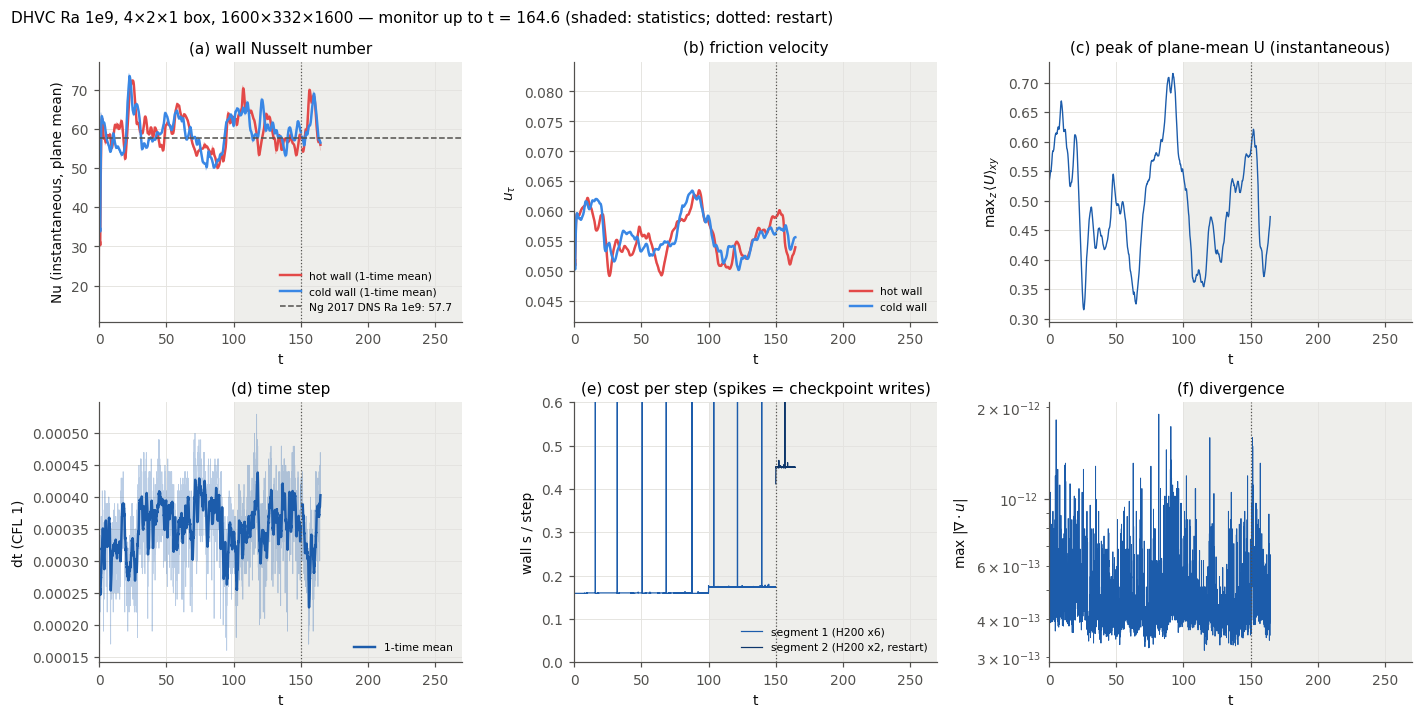

In [ ]:
T_MAX = max(s["mon"]["end_time"] for s in SEGMENTS)
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
for i, s in enumerate(SEGMENTS):
    mm = s["mon"]; tt = mm["time"]; n_avg = max(1, int(round(1.0 / (100 * float(np.mean(mm["dt"]))))))
    first = i == 0
    for key, col, name in (("Nu_hot", HOT, "hot wall"), ("Nu_cold", COLD, "cold wall")):
        axes[0, 0].plot(tt, mm[key], color=col, lw=0.5, alpha=0.3)
        axes[0, 0].plot(tt, running_mean(mm[key], n_avg), color=col, label=f"{name} (1-time mean)" if first else None)
    for key, col, name in (("u_tau_hot", HOT, "hot wall"), ("u_tau_cold", COLD, "cold wall")):
        axes[0, 1].plot(tt, mm[key], color=col, lw=0.5, alpha=0.3)
        axes[0, 1].plot(tt, running_mean(mm[key], n_avg), color=col, label=name if first else None)
    axes[0, 2].plot(tt, mm["u_max"], color=MAIN, lw=0.9)
    axes[1, 0].plot(tt, mm["dt"], color=MAIN, lw=0.5, alpha=0.3)
    axes[1, 0].plot(tt, running_mean(mm["dt"], n_avg), color=MAIN, label="1-time mean" if first else None)
    axes[1, 1].plot(tt, mm["sec/step"], color=MAIN if first else SEG2, lw=0.8, label=s["short"])
    axes[1, 2].semilogy(tt, mm["max|div|"], color=MAIN, lw=0.6)
axes[0, 0].axhline(NG["Nu"], color=NGC, ls="--", lw=1, label=f"Ng 2017 DNS Ra 1e9: {NG['Nu']:.1f}")
axes[0, 0].set(ylabel="Nu (instantaneous, plane mean)", title="(a) wall Nusselt number")
axes[0, 1].set(ylabel=r"$u_\tau$", title="(b) friction velocity")
axes[0, 2].set(ylabel=r"max$_z\,\langle U\rangle_{xy}$", title="(c) peak of plane-mean U (instantaneous)")
axes[1, 0].set(ylabel="dt (CFL 1)", title="(d) time step")
sp = np.concatenate([s["mon"]["sec/step"] for s in SEGMENTS])
axes[1, 1].set_ylim(0, max(0.6, 1.15 * np.nanpercentile(sp, 99)))
axes[1, 1].set(ylabel="wall s / step", title="(e) cost per step (spikes = checkpoint writes)")
axes[1, 2].set(ylabel=r"max $|\nabla\cdot u|$", title="(f) divergence")
for ax in axes.flat:
    ax.axvspan(T_STATS, T_MAX, color=GRID, alpha=0.6, lw=0, zorder=0)
    for s in SEGMENTS[1:]: ax.axvline(s["mon"]["time"][0], color=MUTED, lw=0.8, ls=":")
    ax.set_xlim(0, T_MAX); ax.set_xlabel("t")
    if ax.get_legend_handles_labels()[0]: ax.legend(loc="lower right", fontsize=7)
fig.suptitle(f"DHVC Ra 1e9, 4×2×1 box, 1600×332×1600 — monitor up to t = {SEGMENTS[-1]['mon']['time'][-1]:.1f} "
             "(shaded: statistics; dotted: restart)", x=0.01, ha="left", fontsize=10)
fig.tight_layout(); plt.show()

### 1b. Re_δ* (전단 레이놀즈 수)

Re_δ* = U δ*/ν, U = max 평균 u(z), δ* = ∫₀^{z(U)} (1 − u/U) dz (`apps/dhvc/statistics.cpp` 와 같은 정의, 뜨거운 벽 z = 0 쪽; 차가운 벽은 z → 1 − z, u → −u).
- **점(체크포인트)**: 체크포인트 순간 장의 평면 평균 U(z) — 순간값이라 크게 흔들린다 (5만 스텝마다). U 장만 읽고 `log/re_dstar_ckpt_1e9_box.csv` 에 캐시.
- **가로 막대(블록)**: 통계 파일 사이 25 time 블록의 평균 U(z) 로 계산한 값 (같은 구간 누적 파일 두 개의 차 = 그 블록만의 평균). 두 벽 평균.
- **진한 선(합산 누적)**: t 100 부터 그 시점까지 모든 구간을 dt 가중으로 합친 평균 U(z) 의 값 — **비교 대상**.
- 옅은 선: 각 구간 모니터의 Re_dstar (그 구간만의 누적 — 재시작마다 새로 시작).

In [ ]:
NZ, LZ, GAMMA = 1600, 1.0, 2.6
xi = np.arange(NZ + 1) / NZ
faces = 0.5 * LZ * (1 + np.tanh(0.5 * GAMMA * (2 * xi - 1)) / np.tanh(0.5 * GAMMA)); faces[0], faces[-1] = 0, LZ
zc = 0.5 * (faces[:-1] + faces[1:])

def re_dstar(u, z, nu=NU_VISC):
    k = int(np.argmax(u)); U = u[k]
    if U <= 0: return 0.0, 0.0, 0.0
    zz = np.concatenate(([0.0], z[:k + 1])); ff = np.concatenate(([1.0], 1 - u[:k + 1] / U))
    ds = float(np.sum(0.5 * (ff[1:] + ff[:-1]) * np.diff(zz)))
    return U * ds / nu, U, ds
def re_both(u, z): return re_dstar(u, z)[0], re_dstar(-u[::-1], 1 - z[::-1])[0]

# ── 통계 합산: 평균은 dt 가중 평균, rms·공분산은 2차 모멘트로 ──
MEANS = ("U", "V", "W", "T"); RMS = {"urms": "U", "vrms": "V", "wrms": "W", "trms": "T"}; COV = {"uw": ("U", "W"), "uT": ("U", "T"), "wT": ("W", "T")}
def to_moments(p):
    mo = {k: p[k] for k in MEANS}
    for r, a in RMS.items(): mo[r] = p[r]**2 + p[a]**2
    for c, (a, b) in COV.items(): mo[c] = p[c] + p[a] * p[b]
    return mo
def from_moments(mo, z):
    p = {"z": z}; p.update({k: mo[k] for k in MEANS})
    for r, a in RMS.items(): p[r] = np.sqrt(np.maximum(mo[r] - mo[a]**2, 0))
    for c, (a, b) in COV.items(): p[c] = mo[c] - mo[a] * mo[b]
    return p
def finish(p, h):
    h["Re_dstar"], h["Re_dstar_cold"] = re_both(p["U"], p["z"])
    h["Re_rms"] = p["urms"][int(np.argmax(p["U"]))] / NU_VISC      # U_rms(δ_max)·H/ν, H = 1
    h["nu"] = NU_VISC
    return p, h
def combine(parts):
    """parts = [(weight, profile, head)] → dt 가중 합집합의 (profile, head)."""
    W = sum(w for w, _, _ in parts); mos = [(w, to_moments(p)) for w, p, _ in parts]
    p = from_moments({k: sum(w * mo[k] for w, mo in mos) / W for k in mos[0][1]}, parts[0][1]["z"])
    h = dict(sum_dt=W, t_start=min(hh["t_start"] for _, _, hh in parts), t=max(hh["t"] for _, _, hh in parts))
    for key in ("Nu_hot", "Nu_cold"): h[key] = sum(w * hh[key] for w, _, hh in parts) / W                   # 평균 T 에 선형
    for key in ("u_tau_hot", "u_tau_cold"): h[key] = math.sqrt(sum(w * hh[key]**2 for w, _, hh in parts) / W)  # u_τ² 가 평균 U 에 선형
    return finish(p, h)
def block(prev, nxt):
    """같은 구간의 누적 파일 두 개 → 그 사이 블록만의 (weight, profile, head)."""
    w1, w2 = prev["head"]["sum_dt"], nxt["head"]["sum_dt"]; w = w2 - w1
    m1, m2 = to_moments(prev["prof"]), to_moments(nxt["prof"])
    p = from_moments({k: (w2 * m2[k] - w1 * m1[k]) / w for k in m1}, nxt["prof"]["z"])
    h = dict(sum_dt=w, t_start=prev["head"]["t"], t=nxt["head"]["t"])
    for key in ("Nu_hot", "Nu_cold"): h[key] = (w2 * nxt["head"][key] - w1 * prev["head"][key]) / w
    for key in ("u_tau_hot", "u_tau_cold"): h[key] = math.sqrt(max(0.0, (w2 * nxt["head"][key]**2 - w1 * prev["head"][key]**2) / w))
    p, h = finish(p, h)
    return w, p, h

# 자체 검증: 1구간의 (100~125 누적) + (125~150 블록) = 1구간 최종 (100~150)
s1 = SEGMENTS[0]["stats"]
if len(s1) >= 2:
    w_b, p_b, h_b = block(s1[0], s1[1])
    p_c, h_c = combine([(s1[0]["head"]["sum_dt"], s1[0]["prof"], s1[0]["head"]), (w_b, p_b, h_b)])
    err = max(np.max(np.abs(p_c[k] - s1[1]["prof"][k])) / max(np.max(np.abs(s1[1]["prof"][k])), 1e-30) for k in ("U", "T", "urms", "wrms", "uT", "wT"))
    print(f"합산 식 자체 검증 (1구간 100~125 누적 + 125~150 블록 vs 1구간 최종 파일): 프로파일 최대 상대차 {err:.1e}, "
          f"Re_δ* {h_c['Re_dstar']:.4f} vs 파일 {s1[1]['head']['Re_dstar']:.4f}, Nu_hot {h_c['Nu_hot']:.4f} vs {s1[1]['head']['Nu_hot']:.4f}, "
          f"Re_rms {h_c['Re_rms']:.1f} vs {s1[1]['head']['Re_rms']:.1f}")

# 블록 목록 (모든 구간, 시간순) 과 합산 누적
BLOCKS = []
for s in SEGMENTS:
    st = s["stats"]
    if not st: continue
    h0 = dict(st[0]["head"]); BLOCKS.append((h0["sum_dt"], st[0]["prof"], finish(dict(st[0]["prof"]), h0)[1]))
    for a, b in zip(st[:-1], st[1:]): BLOCKS.append(block(a, b))
CUM = [combine(BLOCKS[:i]) for i in range(1, len(BLOCKS) + 1)]
if CUM: TOTAL_P, TOTAL_H = CUM[-1]

# 체크포인트 순간 Re_δ*
def checkpoint_u_profile(path, chunk=32):
    with open(path, "rb") as f:
        f.read(8); struct.unpack("ii", f.read(8)); step, tt = struct.unpack("qd", f.read(16))
        ngx, ngy, ngz, nf, ns = struct.unpack("iiiii", f.read(20))
        f.seek(24 * ns, 1); off = f.tell()
        for _ in range(nf):
            name = f.read(16).split(b"\0")[0].decode()
            if name == "U": off = f.tell(); break
            f.seek(8 * ngx * ngy * ngz, 1)
    mm = np.memmap(path, dtype="<f8", mode="r", offset=off, shape=(ngx, ngy, ngz))
    prof = np.zeros(ngz)
    for i0 in range(0, ngx, chunk): prof += mm[i0:i0 + chunk].sum(axis=(0, 1))
    return step, tt, prof / (ngx * ngy)
CACHE = os.path.join(APP, "log", "re_dstar_ckpt_1e9_box.csv")
done = {}
for path in [CACHE] + glob.glob(os.path.join(APP, "log", "re_dstar_ckpt_9*.csv")):
    if os.path.exists(path):
        for line in open(path):
            if line.startswith("#"): continue
            v = line.split(","); done[int(v[0])] = [float(x) for x in v[1:]]
for path in sorted(glob.glob(os.path.join(APP, "restart_1e9_box", "dhvc_ck_*.bin"))):
    step = int(re.search(r"_(\d+)\.bin$", path).group(1))
    if step in done: continue
    step, tt, u = checkpoint_u_profile(path)
    rh, uh, dh = re_dstar(u, zc); rc, uc, dc = re_dstar(-u[::-1], 1 - zc[::-1])
    done[step] = [tt, rh, uh, dh, rc, uc, dc]
with open(CACHE, "w") as f:
    f.write("# step,t,Re_dstar_hot,U_hot,dstar_hot,Re_dstar_cold,U_cold,dstar_cold\n")
    for k in sorted(done): f.write(",".join([str(k)] + [f"{x:.8g}" for x in done[k]]) + "\n")
ck = np.array([[k] + done[k] for k in sorted(done)]) if done else np.zeros((0, 8))

print(f"\n{'':24} {'sum_dt':>7} {'Re_δ* hot':>10} {'Re_δ* cold':>11} {'Nu_hot':>8} {'Nu_cold':>8} {'Re_rms':>7}")
for w, p, h in BLOCKS:
    print(f"블록 t {h['t_start']:6.1f} ~ {h['t']:6.1f}    {w:7.2f} {h['Re_dstar']:10.2f} {h['Re_dstar_cold']:11.2f} {h['Nu_hot']:8.2f} {h['Nu_cold']:8.2f} {h['Re_rms']:7.0f}")
if CUM:
    print(f"{'합산 t %.0f ~ %.1f' % (TOTAL_H['t_start'], TOTAL_H['t']):<24} {TOTAL_H['sum_dt']:7.2f} {TOTAL_H['Re_dstar']:10.2f} "
          f"{TOTAL_H['Re_dstar_cold']:11.2f} {TOTAL_H['Nu_hot']:8.2f} {TOTAL_H['Nu_cold']:8.2f} {TOTAL_H['Re_rms']:7.0f}")
re_blocks = np.array([0.5 * (h["Re_dstar"] + h["Re_dstar_cold"]) for _, _, h in BLOCKS])
if len(re_blocks) > 1:
    print(f"블록 값(두 벽 평균) 표준편차 {re_blocks.std(ddof=1):.1f} → 합산 평균의 대략 표준오차 ±{re_blocks.std(ddof=1) / math.sqrt(len(re_blocks)):.1f} "
          f"(블록 {len(re_blocks)}개를 독립으로 본 값)")
print(f"참조: Re_δ* Ng 2017 DNS {NG['Re_dstar_dns']}, Ng 상관식 {NG['Re_dstar_fit']:.1f}, PaScaL_TCS {PASCAL_RE};  Nu Ng DNS {NG['Nu']};  Re_rms Ng DNS {NG['Re_rms']:.0f}")

합산 식 자체 검증 (1구간 100~125 누적 + 125~150 블록 vs 1구간 최종 파일): 프로파일 최대 상대차 5.1e-15, Re_δ* 60.8384 vs 파일 60.8384, Nu_hot 59.7420 vs 59.7420, Re_rms 9262.0 vs 9262.0

                          sum_dt  Re_δ* hot  Re_δ* cold   Nu_hot  Nu_cold  Re_rms
블록 t  100.0 ~  125.0      25.00      53.57       54.72    62.20    62.45    9225
블록 t  125.0 ~  150.0      25.00      68.25       64.82    57.28    58.63    9051
합산 t 100 ~ 150.0           50.00      60.84       59.73    59.74    60.54    9262
블록 값(두 벽 평균) 표준편차 8.8 → 합산 평균의 대략 표준오차 ±6.2 (블록 2개를 독립으로 본 값)
참조: Re_δ* Ng 2017 DNS 58.6, Ng 상관식 76.2, PaScaL_TCS 63.0;  Nu Ng DNS 57.7;  Re_rms Ng DNS 9038


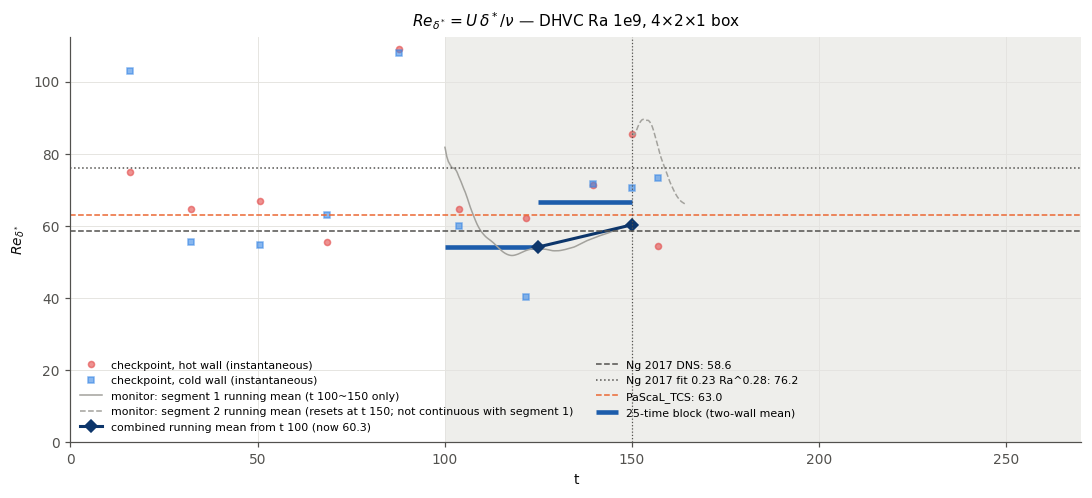

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.6))
if len(ck):
    ax.plot(ck[:, 1], ck[:, 2], "o", color=HOT, ms=4, alpha=0.6, label="checkpoint, hot wall (instantaneous)")
    ax.plot(ck[:, 1], ck[:, 5], "s", color=COLD, ms=4, alpha=0.6, label="checkpoint, cold wall (instantaneous)")
for i, s in enumerate(SEGMENTS):
    mm = s["mon"]; on = mm["Re_dstar"] > 0
    if on.any(): ax.plot(mm["time"][on], mm["Re_dstar"][on], color=REF, lw=1, ls="-" if i == 0 else "--",
                         label=("monitor: segment 1 running mean (t 100~150 only)" if i == 0 else
                                f"monitor: segment 2 running mean (resets at t {mm['time'][0]:.0f}; not continuous with segment 1)"))
for j, (w, p, h) in enumerate(BLOCKS):
    ax.hlines(0.5 * (h["Re_dstar"] + h["Re_dstar_cold"]), h["t_start"], h["t"], color=MAIN, lw=3,
              label="25-time block (two-wall mean)" if j == 0 else None)
if CUM:
    tt = [h["t"] for _, h in CUM]; rr = [0.5 * (h["Re_dstar"] + h["Re_dstar_cold"]) for _, h in CUM]
    ax.plot(tt, rr, "D-", color=SEG2, ms=6, lw=2, label=f"combined running mean from t 100 (now {rr[-1]:.1f})")
ax.axhline(NG["Re_dstar_dns"], color=NGC, ls="--", lw=1, label=f"Ng 2017 DNS: {NG['Re_dstar_dns']}")
ax.axhline(NG["Re_dstar_fit"], color=NGC, ls=":", lw=1, label=f"Ng 2017 fit 0.23 Ra^0.28: {NG['Re_dstar_fit']:.1f}")
ax.axhline(PASCAL_RE, color=PAS, ls="--", lw=1, label=f"PaScaL_TCS: {PASCAL_RE}")
ax.axvspan(T_STATS, T_MAX, color=GRID, alpha=0.6, lw=0, zorder=0)
for s in SEGMENTS[1:]: ax.axvline(s["mon"]["time"][0], color=MUTED, lw=0.8, ls=":")
ax.set_xlim(0, T_MAX); ax.set_ylim(0, None); ax.set_xlabel("t"); ax.set_ylabel(r"$Re_{\delta^*}$")
ax.set_title(r"$Re_{\delta^*} = U\,\delta^*/\nu$ — DHVC Ra 1e9, 4×2×1 box"); ax.legend(loc="lower left", fontsize=7.2, ncol=2)
fig.tight_layout(); plt.show()

## 2. 통계 프로파일 (모든 구간 합산)

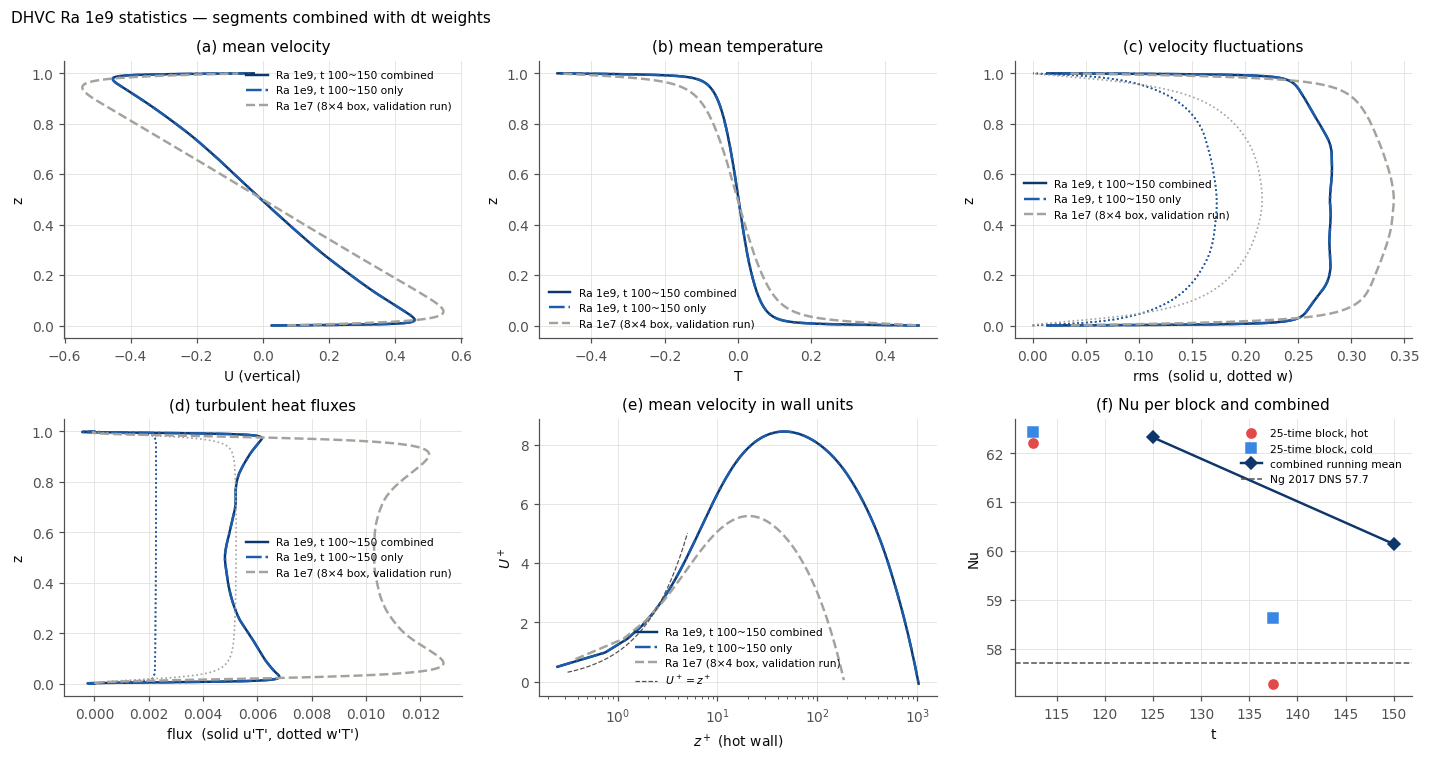

In [ ]:
ref_paths = sorted(glob.glob(os.path.join(REF_DIR, "dhvc_stats_*.dat")))
RUNS = []
if CUM:
    RUNS.append(dict(label=f"Ra 1e9, t {TOTAL_H['t_start']:.0f}~{TOTAL_H['t']:.0f} combined", color=SEG2, ls="-", prof=TOTAL_P, head=TOTAL_H))
    if SEGMENTS[0]["stats"]:
        s1f = SEGMENTS[0]["stats"][-1]
        RUNS.append(dict(label="Ra 1e9, t 100~150 only", color=MAIN, ls="-.", prof=s1f["prof"], head=s1f["head"]))
else:
    print("Ra 1e9 통계 파일 없음.")
if ref_paths:
    r = read_stats(ref_paths[-1]); RUNS.append(dict(label="Ra 1e7 (8×4 box, validation run)", color=REF, ls="--", prof=r["prof"], head=r["head"]))
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for r in RUNS:
    p, h = r["prof"], r["head"]; z = p["z"]; kw = dict(color=r["color"], ls=r["ls"], label=r["label"])
    axes[0, 0].plot(p["U"], z, **kw)
    axes[0, 1].plot(p["T"], z, **kw)
    axes[0, 2].plot(p["urms"], z, **kw); axes[0, 2].plot(p["wrms"], z, color=r["color"], ls=":", lw=1.1)
    axes[1, 0].plot(p["uT"], z, **kw); axes[1, 0].plot(p["wT"], z, color=r["color"], ls=":", lw=1.1)
    hot = z < 0.5; nu = h.get("nu", NU_VISC)
    axes[1, 1].semilogx(z[hot] * h["u_tau_hot"] / nu, p["U"][hot] / h["u_tau_hot"], **kw)
zz = np.logspace(-0.5, 0.7, 30); axes[1, 1].plot(zz, zz, color=NGC, lw=0.8, ls="--", label=r"$U^+ = z^+$")
if BLOCKS:
    tb = [0.5 * (h["t_start"] + h["t"]) for _, _, h in BLOCKS]
    axes[1, 2].plot(tb, [h["Nu_hot"] for _, _, h in BLOCKS], "o", color=HOT, label="25-time block, hot")
    axes[1, 2].plot(tb, [h["Nu_cold"] for _, _, h in BLOCKS], "s", color=COLD, label="25-time block, cold")
    axes[1, 2].plot([h["t"] for _, h in CUM], [0.5 * (h["Nu_hot"] + h["Nu_cold"]) for _, h in CUM], "D-", color=SEG2, label="combined running mean")
axes[1, 2].axhline(NG["Nu"], color=NGC, ls="--", lw=1, label=f"Ng 2017 DNS {NG['Nu']}")
axes[0, 0].set(xlabel="U (vertical)", ylabel="z", title="(a) mean velocity")
axes[0, 1].set(xlabel="T", ylabel="z", title="(b) mean temperature")
axes[0, 2].set(xlabel="rms  (solid u, dotted w)", ylabel="z", title="(c) velocity fluctuations")
axes[1, 0].set(xlabel="flux  (solid u'T', dotted w'T')", ylabel="z", title="(d) turbulent heat fluxes")
axes[1, 1].set(xlabel=r"$z^+$ (hot wall)", ylabel=r"$U^+$", title="(e) mean velocity in wall units")
axes[1, 2].set(xlabel="t", ylabel="Nu", title="(f) Nu per block and combined")
for ax in axes.flat: ax.legend(loc="best", fontsize=7)
fig.suptitle("DHVC Ra 1e9 statistics — segments combined with dt weights", x=0.01, ha="left", fontsize=10)
fig.tight_layout(); plt.show()